# Zela Aí — Análise descritiva das solicitações de zeladoria do SP156
**Global Solution 2026.2 · CitizenTech · Data Science & Statistical Computing · Engenharia de Software (2º ano)**

| Ficha da CitizenTech | |
|---|---|
| **Nome** | Zela Aí |
| **Cidade** | São Paulo (SP) — foco na região da FIAP Paulista (Subprefeitura Sé) |
| **Cidadão beneficiado** | Morador de bairro da cidade de São Paulo |
| **Problema, em uma frase** | O morador vê o problema na rua, mas não sabe se alguém já reclamou, não acompanha o andamento e não entende por que outros pedidos são atendidos antes do dele. |
| **Como funciona** | Moradores registram problemas da rua (buraco, entulho, bueiro, calçada…), vizinhos apoiam o registro e o sistema calcula o que deve ser resolvido primeiro; todos acompanham o andamento até a resolução. |
| **Papel desta entrega** | Usar dados reais do SP156 para entender a realidade da zeladoria hoje e gerar os parâmetros (tempo e volume por categoria) que alimentam a priorização. |
| **ODS** | 11 (Cidades e comunidades sustentáveis), 9 (Indústria, inovação e infraestrutura), 10 (Redução das desigualdades) |

**Integrantes:** Gabriel Cutrim (RM 568059) · Guilherme Pereira (RM 567487) · Gustavo Firmino (RM 566903)

## 1. Contexto e perguntas de negócio

O SP156 é o principal canal de solicitações de serviços da Prefeitura de São Paulo. Ele já recebe pedidos de zeladoria, mas o cidadão
vê apenas o próprio protocolo: não sabe se outros vizinhos já reclamaram do mesmo problema nem por que um pedido é atendido antes do outro.
O **Zela Aí** não substitui o 156; ele o complementa com **apoio coletivo**, **priorização transparente** e **visão do bairro**.

Para desenhar essa solução com base em evidências, a análise responde a seis perguntas:

| # | Pergunta de negócio | Por que importa para o Zela Aí |
|---|---|---|
| P1 | Quais problemas de zeladoria mais geram solicitações? | Define as categorias da plataforma e onde está o maior volume. |
| P2 | Quanto tempo a Prefeitura leva para resolver cada tipo de problema? | O tempo típico mostra quanto tempo de equipe cada tipo de ocorrência consome, um dado essencial para priorizar. |
| P3 | Quantos pedidos continuam sem solução e há quanto tempo? | Mostra o tamanho da fila que o morador não enxerga hoje. |
| P4 | O atendimento é igual em todas as regiões da cidade? | Testa se há desigualdade territorial (ODS 10). |
| P5 | Moradores reclamam várias vezes do mesmo ponto? | Se sim, o "apoio" de vizinhos substitui protocolos duplicados. |
| P6 | Por quais canais o cidadão pede ajuda? | Indica se um canal digital/mobile tem aderência. |

## 2. Base de dados

**Fonte:** Portal de Dados Abertos da Prefeitura de São Paulo — conjunto *Dados do SP156 - Solicitações*, arquivo **"Dados do SP156 - 3° TRI 2026"**
(solicitações abertas entre 01/07/2026 e 30/09/2026; status extraído pela Prefeitura em 19/10/2026).

- Página: https://dados.prefeitura.sp.gov.br/dataset/dados-do-sp156
- CSV original (≈106 MB, 484.232 solicitações, 15 colunas): https://dados.prefeitura.sp.gov.br/dataset/0aecfa2b-aa3a-40d4-8183-0d4351b7fd0a/resource/f67fcc12-8da4-485f-92a3-d2af40cc771e/download/arquivo-final-3-trim-26.csv
- Dicionário de dados: *Dicionário dados abertos - SP156 2020 em diante* (mesma página).

A base é **pública e anonimizada pela Prefeitura** (sem nome, CPF ou contato do solicitante). Não usamos nenhum dado pessoal.

**Recorte usado (`zelaai_sp156_zeladoria_3tri2026.csv`):** apenas os serviços de zeladoria de rua, agrupados em 6 categorias do Zela Aí.
Foram removidas as colunas de endereço exato (logradouro, número e CEP); mantivemos latitude/longitude, subprefeitura e distrito.

| Coluna | Significado |
|---|---|
| `data_abertura` / `data_finalizacao` | Abertura e fechamento do protocolo (vazia se ainda aberto) |
| `canal` | Meio de comunicação: MOBILE (app), PORTAL, CRM (central telefônica) ou CHATBOT |
| `tema`, `assunto`, `servico` | Classificação oficial da Carta de Serviços |
| `categoria_zelaai` | Categoria criada pela equipe a partir de `servico` |
| `status` | Situação na data da extração (Finalizada, Aberto, Cancelada) |
| `orgao` | Órgão responsável no momento da extração |
| `latitude`, `longitude` | Local do problema |
| `subprefeitura`, `distrito` | Divisão administrativa do local |

O recorte pode ser **reproduzido** a partir do CSV original com a função abaixo (deixamos a execução desligada porque o arquivo original é grande).

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

URL_ORIGINAL = ("https://dados.prefeitura.sp.gov.br/dataset/0aecfa2b-aa3a-40d4-8183-0d4351b7fd0a/"
                "resource/f67fcc12-8da4-485f-92a3-d2af40cc771e/download/arquivo-final-3-trim-26.csv")
ARQUIVO = "zelaai_sp156_zeladoria_3tri2026.csv"
DATA_EXTRACAO = pd.Timestamp("2026-10-19")   # data em que a Prefeitura extraiu os status

# Serviço oficial do SP156  ->  categoria do Zela Aí
MAPA_CATEGORIAS = [
    (r"^Tapa-buraco", "Buraco na via"),
    (r"^Entulho e grandes objetos em via p|Denunciar descarte irregular de entulho|Denunciar caçamba irregular",
     "Descarte irregular / entulho"),
    (r"falta de varrição|Sacos de varrição|Lixeiras públicas - solicitar|Instalação e remoção de lixeira",
     "Limpeza urbana e lixeiras"),
    (r"limpeza de bueiros", "Bueiro entupido"),
    (r"Calçada pública - solicitar manutenção|Guias, sarjetas e sarjetões|obstáculo na calçada|Denunciar Fiação solta|Poste em mau estado",
     "Calçada, guia e poste"),
    (r"^Árvore – Solicitar avaliação em calçadas", "Árvore em via pública"),
]

def categorizar(servico: str):
    for padrao, categoria in MAPA_CATEGORIAS:
        if re.search(padrao, str(servico), flags=re.IGNORECASE):
            return categoria
    return None

def gerar_recorte(origem=URL_ORIGINAL, destino=ARQUIVO):
    """Lê o CSV oficial do SP156 e grava o recorte de zeladoria usado nesta análise."""
    bruto = pd.read_csv(origem, dtype=str)
    bruto["categoria_zelaai"] = bruto["Serviço"].map(categorizar)
    z = bruto.dropna(subset=["categoria_zelaai"]).copy()
    for col in ["Data de Abertura", "Data de Finalização"]:          # datas vêm em MM/DD/AAAA
        z[col] = pd.to_datetime(z[col], format="%m/%d/%Y").dt.strftime("%Y-%m-%d")
    z = z.rename(columns={"Data de Abertura": "data_abertura", "Data de Finalização": "data_finalizacao",
                          "Meio de Comunicação": "canal", "Tema": "tema", "Assunto": "assunto",
                          "Serviço": "servico", "Status": "status", "Órgão": "orgao",
                          "Latitude": "latitude", "Longitude": "longitude",
                          "Prefeitura Operacional": "subprefeitura", "Distrito": "distrito"})
    colunas = ["data_abertura", "data_finalizacao", "canal", "tema", "assunto", "servico", "categoria_zelaai",
               "status", "orgao", "latitude", "longitude", "subprefeitura", "distrito"]
    z[colunas].to_csv(destino, index=False)
    return z[colunas]

# gerar_recorte()   # descomente para refazer o recorte a partir do arquivo original

In [2]:
# Identidade visual dos gráficos
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#b8b6ae"
plt.rcParams.update({
    "figure.figsize": (9, 4.6), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left", "axes.grid": True,
    "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10,
})
pd.set_option("display.float_format", lambda v: f"{v:,.2f}".replace(",", "X").replace(".", ",").replace("X", "."))
br = lambda v, casas=0: f"{v:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")   # número no formato brasileiro

df_bruto = pd.read_csv(ARQUIVO)
print(f"{br(len(df_bruto))} solicitações · {df_bruto.shape[1]} colunas")
df_bruto.head()

113.995 solicitações · 13 colunas


,data_abertura,data_finalizacao,canal,tema,assunto,servico,categoria_zelaai,status,orgao,latitude,longitude,subprefeitura,distrito
0,2026-07-01,2026-10-01,MOBILE,Meio Ambiente,Árvore,Árvore – Solicitar avaliação em calçadas e pra...,Árvore em via pública,Finalizada,INTEGRAÇÃO-SMGI/SGZ,"-23,43","-46,80",PERUS-ANHANGUERA,ANHANGUERA
1,2026-07-01,2026-10-01,MOBILE,Meio Ambiente,Árvore,Árvore – Solicitar avaliação em calçadas e pra...,Árvore em via pública,Finalizada,INTEGRAÇÃO-SMGI/SGZ,"-23,43","-46,80",PERUS-ANHANGUERA,ANHANGUERA
2,2026-07-01,2026-09-17,CRM,Meio Ambiente,Árvore,Árvore – Solicitar avaliação em calçadas e pra...,Árvore em via pública,Finalizada,INTEGRAÇÃO-SMGI/SGZ,"-23,61","-46,72",BUTANTA,MORUMBI
3,2026-07-01,2026-07-14,PORTAL,Rua e bairro,"Reparos em Asfalto, Pontes, Viadutos e Túneis",Tapa-buraco,Buraco na via,Finalizada,INTEGRAÇÃO-SMGI/SGZ,"-23,61","-46,71",BUTANTA,MORUMBI
4,2026-07-01,2026-07-14,PORTAL,Rua e bairro,"Reparos em Asfalto, Pontes, Viadutos e Túneis",Tapa-buraco,Buraco na via,Finalizada,INTEGRAÇÃO-SMGI/SGZ,"-23,61","-46,71",BUTANTA,MORUMBI


## 3. Preparação dos dados

In [3]:
df_bruto.info()
print("\nValores ausentes por coluna:")
df_bruto.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 113995 entries, 0 to 113994
Data columns (total 13 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   data_abertura     113995 non-null  object 
 1   data_finalizacao  91320 non-null   object 
 2   canal             113995 non-null  object 
 3   tema              113995 non-null  object 
 4   assunto           113995 non-null  object 
 5   servico           113995 non-null  object 
 6   categoria_zelaai  113995 non-null  object 
 7   status            113995 non-null  object 
 8   orgao             113995 non-null  object 
 9   latitude          113989 non-null  float64
 10  longitude         113989 non-null  float64
 11  subprefeitura     113872 non-null  object 
 12  distrito          113948 non-null  object 
dtypes: float64(2), object(11)
memory usage: 11.3+ MB

Valores ausentes por coluna:


,0
data_abertura,0
data_finalizacao,22675
canal,0
tema,0
assunto,0
servico,0
categoria_zelaai,0
status,0
orgao,0
latitude,6


In [4]:
df = df_bruto.copy()
log = {}

# 3.1 Tipos: datas
df["data_abertura"] = pd.to_datetime(df["data_abertura"])
df["data_finalizacao"] = pd.to_datetime(df["data_finalizacao"])

# 3.2 Conferência do recorte: toda linha tem a categoria que o mapa produz a partir do serviço
log["categoria divergente do mapa"] = int((df["servico"].map(categorizar) != df["categoria_zelaai"]).sum())

# 3.3 Status padronizado e indicador de pendência
df["status"] = df["status"].replace({"Aberto": "Aberta"})
df["pendente"] = df["status"].eq("Aberta")

# 3.4 Coerência das datas: finalização antes da abertura?
log["finalização antes da abertura"] = int((df["data_finalizacao"] < df["data_abertura"]).sum())

# 3.5 Coordenadas fora dos limites do município (ex.: 0,0) viram ausentes
dentro_sp = df["latitude"].between(-24.01, -23.35) & df["longitude"].between(-46.83, -46.36)
log["coordenadas fora de SP ou vazias"] = int((~dentro_sp).sum())
df.loc[~dentro_sp, ["latitude", "longitude"]] = np.nan

# 3.6 Subprefeitura: a coluna traz alguns órgãos (ex.: usina de asfalto) e "não encontrada" no lugar da região
SUBPREFEITURAS_VALIDAS = df["subprefeitura"].value_counts()
SUBPREFEITURAS_VALIDAS = SUBPREFEITURAS_VALIDAS[SUBPREFEITURAS_VALIDAS > 900].index   # as 32 subprefeituras reais
invalida = ~df["subprefeitura"].isin(SUBPREFEITURAS_VALIDAS)
log["subprefeitura não identificada"] = int(invalida.sum())
df.loc[invalida, "subprefeitura"] = "NÃO IDENTIFICADA"

# 3.7 Variáveis derivadas
df["tempo_resolucao_dias"] = (df["data_finalizacao"] - df["data_abertura"]).dt.days.where(df["status"].eq("Finalizada"))
df["idade_pendente_dias"] = (DATA_EXTRACAO - df["data_abertura"]).dt.days.where(df["pendente"])
df["mes"] = df["data_abertura"].dt.month.map({7: "Jul", 8: "Ago", 9: "Set"})
df["semana"] = df["data_abertura"].dt.to_period("W-SUN").dt.start_time

print(f"Subprefeituras reais: {len(SUBPREFEITURAS_VALIDAS)}")
pd.Series(log, name="linhas afetadas").to_frame()

Subprefeituras reais: 32


,linhas afetadas
categoria divergente do mapa,0
finalização antes da abertura,0
coordenadas fora de SP ou vazias,8
subprefeitura não identificada,501


**Decisões de preparação**
- As datas viraram `datetime`; o recorte foi conferido linha a linha contra o mapa de categorias.
- Nenhuma linha foi apagada: dados problemáticos foram marcados como ausentes ou "NÃO IDENTIFICADA", para não distorcer os volumes.
- `tempo_resolucao_dias` só existe para pedidos **finalizados**. Pedidos ainda abertos entram na pergunta P3 pela `idade_pendente_dias` (dias entre a abertura e a extração de 19/10/2026).
- **Atenção (viés de censura):** como os pedidos abertos não têm tempo de resolução, a média dos finalizados **subestima** o tempo real, principalmente nas categorias com muita pendência.

## 4. Análise descritiva
### P1 — Quais problemas de zeladoria mais geram solicitações?

In [5]:
freq = (df["categoria_zelaai"].value_counts().rename("solicitações").to_frame()
          .assign(**{"% do total": lambda t: 100 * t["solicitações"] / t["solicitações"].sum()}))
freq["% acumulado"] = freq["% do total"].cumsum()
display(freq)

media_dia = df.groupby(df["data_abertura"].dt.date).size()
print(f"Média de {br(media_dia.mean())} solicitações de zeladoria por dia "
      f"(mediana {br(media_dia.median())}, desvio-padrão {br(media_dia.std())}). "
      "A mediana fica acima da média porque fins de semana têm bem menos pedidos.")

,solicitações,% do total,% acumulado
categoria_zelaai,,,
Descarte irregular / entulho,34265,"30,06","30,06"
Buraco na via,29962,"26,28","56,34"
Árvore em via pública,17570,"15,41","71,75"
Limpeza urbana e lixeiras,14274,"12,52","84,28"
"Calçada, guia e poste",12167,"10,67","94,95"
Bueiro entupido,5757,"5,05","100,00"


Média de 1.239 solicitações de zeladoria por dia (mediana 1.369, desvio-padrão 435). A mediana fica acima da média porque fins de semana têm bem menos pedidos.


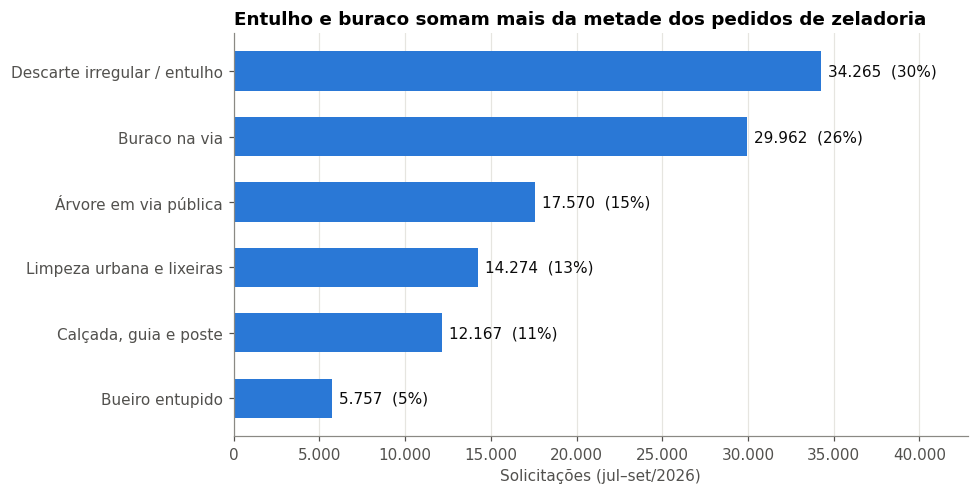

In [6]:
ordem = freq.index[::-1]
fig, ax = plt.subplots()
ax.barh(ordem, freq.loc[ordem, "solicitações"], color=AZUL, height=0.6)
for i, v in enumerate(freq.loc[ordem, "solicitações"]):
    ax.text(v + 400, i, f"{v:,.0f}  ({100*v/len(df):.0f}%)".replace(",", "."), va="center", color="#0b0b0b")
ax.set_title("Entulho e buraco somam mais da metade dos pedidos de zeladoria")
ax.set_xlabel("Solicitações (jul–set/2026)")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, freq["solicitações"].max() * 1.25)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", ".")))
plt.tight_layout(); plt.show()

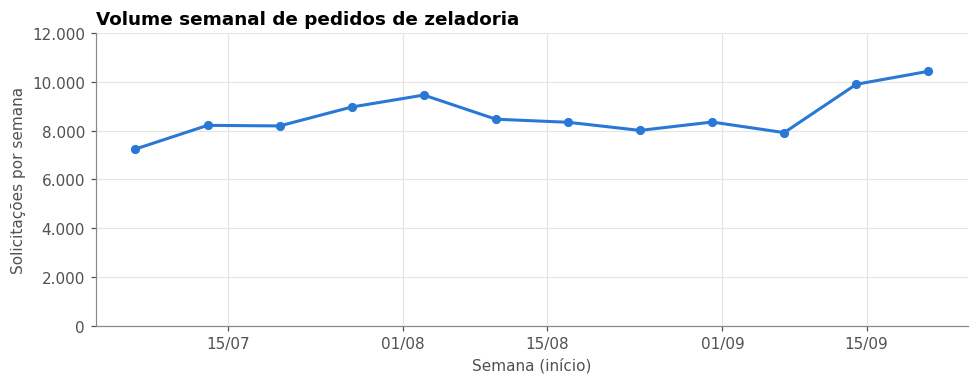

Semanas completas: média 8.628 · mín 7.248 · máx 10.436 · coeficiente de variação 10,5%


In [7]:
semanal = df.groupby("semana").size()
semanal = semanal.iloc[1:-1]   # remove semanas incompletas nas bordas do trimestre
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(semanal.index, semanal.values, color=AZUL, linewidth=2, marker="o", markersize=5)
ax.set_title("Volume semanal de pedidos de zeladoria")
import matplotlib.dates as mdates
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m")); ax.set_xlabel("Semana (início)")
ax.set_ylabel("Solicitações por semana")
ax.set_ylim(0, semanal.max() * 1.15)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", ".")))
plt.tight_layout(); plt.show()
print(f"Semanas completas: média {br(semanal.mean())} · mín {br(semanal.min())} · máx {br(semanal.max())} · "
      f"coeficiente de variação {br(100 * semanal.std() / semanal.mean(), 1)}%")

### P2 — Quanto tempo a Prefeitura leva para resolver cada tipo de problema?

In [8]:
fin = df[df["status"].eq("Finalizada")]

def resumo(s):
    return pd.Series({
        "n": s.count(), "média": s.mean(), "mediana": s.median(), "desvio-padrão": s.std(),
        "CV": s.std() / s.mean(), "Q1": s.quantile(.25), "Q3": s.quantile(.75),
        "IQR": s.quantile(.75) - s.quantile(.25), "P90": s.quantile(.90), "máx": s.max(), "assimetria": s.skew(),
    })

tempo = fin.groupby("categoria_zelaai")["tempo_resolucao_dias"].apply(resumo).unstack().sort_values("mediana")
tempo.loc["TODAS"] = resumo(fin["tempo_resolucao_dias"])
tempo["n"] = tempo["n"].astype(int)
tempo

,n,média,mediana,desvio-padrão,CV,Q1,Q3,IQR,P90,máx,assimetria
categoria_zelaai,,,,,,,,,,,
Bueiro entupido,5204,"4,22","1,00","7,37","1,74","0,00","4,00","4,00","17,00","67,00","2,43"
Descarte irregular / entulho,33314,"2,61","1,00","5,26","2,01","0,00","2,00","2,00","6,00","77,00","3,31"
Limpeza urbana e lixeiras,14186,"2,22","1,00","4,86","2,19","0,00","2,00","2,00","4,00","37,00","3,41"
Buraco na via,21379,"7,68","4,00","9,80","1,28","1,00","11,00","10,00","19,00","91,00","2,75"
"Calçada, guia e poste",4782,"16,78","10,00","18,21","1,09","4,00","22,00","18,00","44,00","97,00","1,72"
Árvore em via pública,12382,"16,68","12,00","15,89","0,95","6,00","22,00","16,00","40,00","98,00","1,70"
TODAS,91247,"6,48","2,00","10,94","1,69","1,00","8,00","7,00","19,00","98,00","3,07"


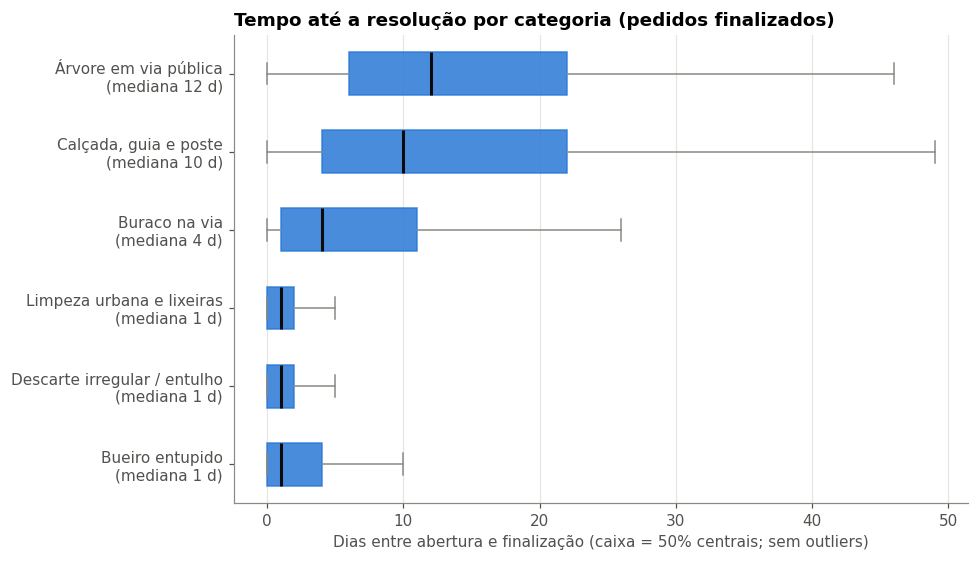

In [9]:
cats = tempo.drop("TODAS").index
dados = [fin.loc[fin["categoria_zelaai"].eq(c), "tempo_resolucao_dias"] for c in cats]
fig, ax = plt.subplots(figsize=(9, 5.2))
rotulos = [f"{c}\n(mediana {tempo.loc[c, 'mediana']:.0f} d)" for c in cats]
bp = ax.boxplot(dados, orientation="horizontal", tick_labels=rotulos, showfliers=False, patch_artist=True, widths=0.55,
                medianprops=dict(color="#0b0b0b", linewidth=2), whiskerprops=dict(color="#8a8984"),
                capprops=dict(color="#8a8984"), boxprops=dict(facecolor=AZUL, edgecolor=AZUL, alpha=0.85))
ax.set_title("Tempo até a resolução por categoria (pedidos finalizados)")
ax.set_xlabel("Dias entre abertura e finalização (caixa = 50% centrais; sem outliers)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

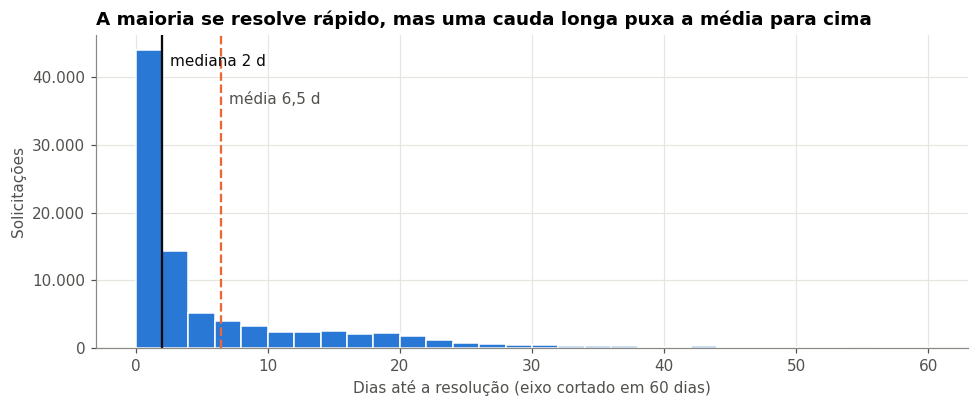

0,7% dos finalizados levaram mais de 60 dias (fora do gráfico).


In [10]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(fin["tempo_resolucao_dias"], bins=range(0, 61, 2), color=AZUL, edgecolor="white", linewidth=1)
med, media = fin["tempo_resolucao_dias"].median(), fin["tempo_resolucao_dias"].mean()
ax.axvline(med, color="#0b0b0b", linewidth=1.5); ax.text(med + 0.6, ax.get_ylim()[1] * .9, f"mediana {med:.0f} d", color="#0b0b0b")
ax.axvline(media, color=LARANJA, linewidth=1.5, linestyle="--"); ax.text(media + 0.6, ax.get_ylim()[1] * .78, f"média {br(media, 1)} d", color="#52514e")
ax.set_title("A maioria se resolve rápido, mas uma cauda longa puxa a média para cima")
ax.set_xlabel("Dias até a resolução (eixo cortado em 60 dias)"); ax.set_ylabel("Solicitações")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", ".")))
plt.tight_layout(); plt.show()
print(f"{br(100 * (fin['tempo_resolucao_dias'] > 60).mean(), 1)}% dos finalizados levaram mais de 60 dias (fora do gráfico).")

### P3 — Quantos pedidos continuam sem solução e há quanto tempo?

In [11]:
pend = (df.groupby("categoria_zelaai")
          .agg(solicitações=("pendente", "size"), pendentes=("pendente", "sum"),
               idade_mediana_pendente=("idade_pendente_dias", "median"))
          .assign(**{"% pendente": lambda t: 100 * t["pendentes"] / t["solicitações"]})
          .sort_values("% pendente", ascending=False))
display(pend)
print(f"No total, {br(df['pendente'].sum())} pedidos ({br(100 * df['pendente'].mean(), 1)}%) seguiam abertos em 19/10/2026; "
      f"metade deles já estava aberta havia pelo menos {df['idade_pendente_dias'].median():.0f} dias.")

,solicitações,pendentes,idade_mediana_pendente,% pendente
categoria_zelaai,,,,
"Calçada, guia e poste",12167,7374,"55,00","60,61"
Árvore em via pública,17570,5179,"47,00","29,48"
Buraco na via,29962,8570,"40,00","28,60"
Bueiro entupido,5757,542,"40,00","9,41"
Descarte irregular / entulho,34265,925,"48,00","2,70"
Limpeza urbana e lixeiras,14274,85,"63,00","0,60"


No total, 22.675 pedidos (19,9%) seguiam abertos em 19/10/2026; metade deles já estava aberta havia pelo menos 47 dias.


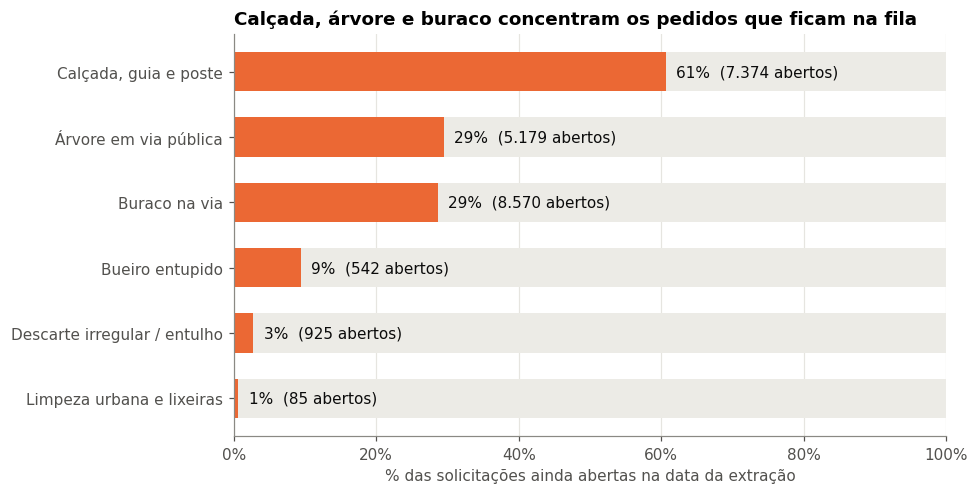

In [12]:
p = pend.sort_values("% pendente")
fig, ax = plt.subplots()
ax.barh(p.index, 100, color="#ecebe6", height=0.6)                       # trilho de 100%
ax.barh(p.index, p["% pendente"], color=LARANJA, height=0.6)
for i, (v, n) in enumerate(zip(p["% pendente"], p["pendentes"])):
    ax.text(max(v, 0) + 1.5, i, f"{v:.0f}%  ({n:,.0f} abertos)".replace(",", "."), va="center", color="#0b0b0b")
ax.set_xlim(0, 100); ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("Calçada, árvore e buraco concentram os pedidos que ficam na fila")
ax.set_xlabel("% das solicitações ainda abertas na data da extração")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

### P4 — O atendimento é igual em todas as regiões da cidade?
Comparamos as 32 subprefeituras no problema central do Zela Aí: **buraco na via**.

In [13]:
reg = df[df["subprefeitura"].ne("NÃO IDENTIFICADA")]
bur = reg[reg["categoria_zelaai"].eq("Buraco na via")]
por_sub = (bur.groupby("subprefeitura")
             .agg(solicitações=("pendente", "size"), pct_pendente=("pendente", "mean"),
                  mediana_dias=("tempo_resolucao_dias", "median"))
             .assign(pct_pendente=lambda t: 100 * t["pct_pendente"])
             .sort_values("pct_pendente", ascending=False))

disp = por_sub[["pct_pendente", "mediana_dias"]].agg(["mean", "std", "min", "max"]).T
disp["CV"] = disp["std"] / disp["mean"]
disp["max / min"] = disp["max"] / disp["min"].replace(0, np.nan)
print("Dispersão entre subprefeituras (buraco na via):")
display(disp)
display(pd.concat([por_sub.head(5), por_sub.tail(5)]))

Dispersão entre subprefeituras (buraco na via):


,mean,std,min,max,CV,max / min
pct_pendente,"28,69","8,55","12,80","52,05","0,30","4,07"
mediana_dias,"4,03","1,38","1,00","7,00","0,34","7,00"


,solicitações,pct_pendente,mediana_dias
subprefeitura,,,
LAPA,1072,"52,05","5,00"
SANTO AMARO,725,"43,03","5,00"
CIDADE ADEMAR,846,"40,07","5,00"
FREGUESIA-BRASILANDIA,659,"39,61","3,00"
M BOI MIRIM,1105,"37,92","4,00"
JACANA-TREMEMBE,853,"21,10","3,00"
ARICANDUVA-FORMOSA-CARRAO,1125,"16,98","5,00"
SAO MATEUS,1581,"16,76","6,00"
SAPOPEMBA,898,"16,59","6,00"


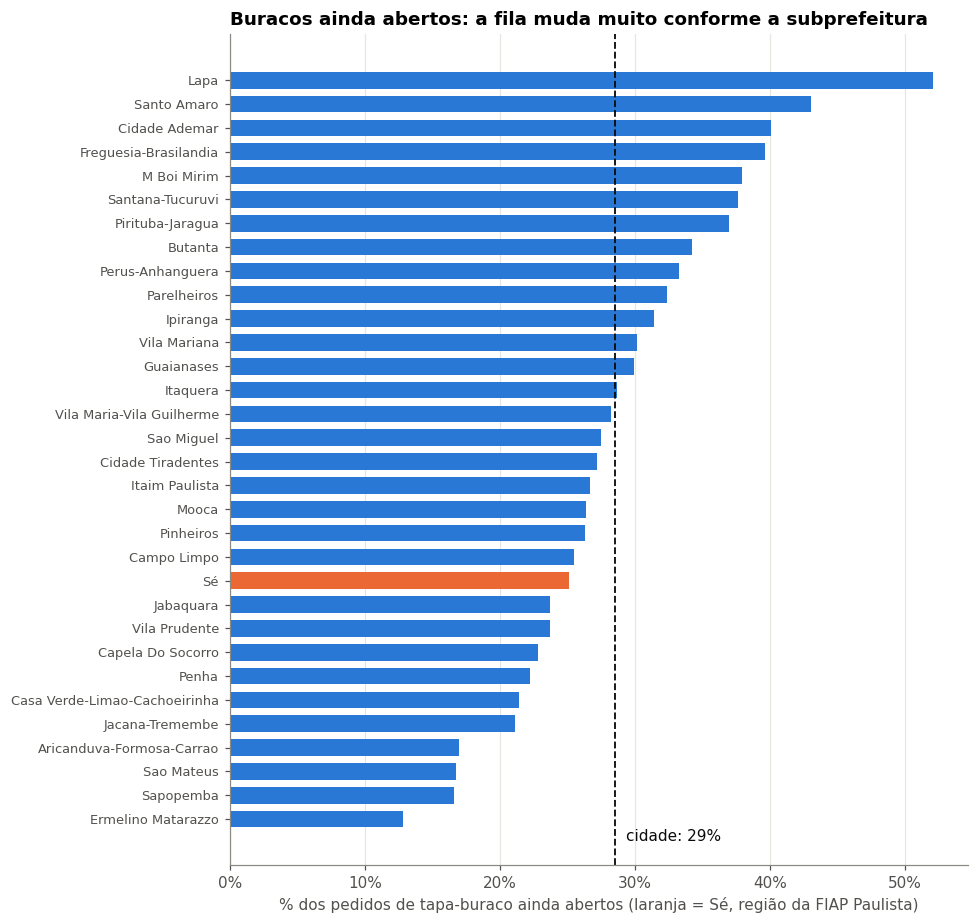

In [14]:
ps = por_sub.sort_values("pct_pendente")
media_cidade = 100 * bur["pendente"].mean()
cores = [LARANJA if s == "SE" else AZUL for s in ps.index]
fig, ax = plt.subplots(figsize=(9, 8.5))
ax.barh(ps.index.str.title().str.replace("^Se$", "Sé", regex=True), ps["pct_pendente"], color=cores, height=0.7)
ax.axvline(media_cidade, color="#0b0b0b", linewidth=1.2, linestyle="--")
ax.text(media_cidade + 0.8, -0.9, f"cidade: {media_cidade:.0f}%", color="#0b0b0b")
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("Buracos ainda abertos: a fila muda muito conforme a subprefeitura")
ax.set_xlabel("% dos pedidos de tapa-buraco ainda abertos (laranja = Sé, região da FIAP Paulista)")
ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=8.5)
plt.tight_layout(); plt.show()

**Foco no território da equipe — Subprefeitura Sé (Bela Vista, Consolação, Liberdade, Cambuci…) comparada à cidade**

In [15]:
def perfil(base):
    return pd.Series({
        "solicitações": len(base),
        "% pendente": 100 * base["pendente"].mean(),
        "mediana dias (finalizados)": base["tempo_resolucao_dias"].median(),
        "média dias (finalizados)": base["tempo_resolucao_dias"].mean(),
    })

se = df[df["subprefeitura"].eq("SE")]
comparativo = pd.DataFrame({"Subprefeitura Sé": perfil(se), "Cidade de SP": perfil(df)})
display(comparativo)

mix = pd.DataFrame({"Sé (%)": se["categoria_zelaai"].value_counts(normalize=True) * 100,
                    "Cidade (%)": df["categoria_zelaai"].value_counts(normalize=True) * 100}).sort_values("Cidade (%)", ascending=False)
display(mix)
display(se["distrito"].value_counts().head(8).rename("solicitações na Sé por distrito").to_frame())

,Subprefeitura Sé,Cidade de SP
solicitações,"4.478,00","113.995,00"
% pendente,"15,07","19,89"
mediana dias (finalizados),"1,00","2,00"
média dias (finalizados),"4,76","6,48"


,Sé (%),Cidade (%)
categoria_zelaai,,
Descarte irregular / entulho,"28,94","30,06"
Buraco na via,"19,14","26,28"
Árvore em via pública,"13,11","15,41"
Limpeza urbana e lixeiras,"19,34","12,52"
"Calçada, guia e poste","10,74","10,67"
Bueiro entupido,"8,73","5,05"


,solicitações na Sé por distrito
distrito,
SANTA CECILIA,811
REPUBLICA,746
LIBERDADE,659
CAMBUCI,564
CONSOLACAO,499
BELA VISTA,421
BOM RETIRO,345
SE,290


### P5 — Moradores reclamam várias vezes do mesmo ponto?
Agrupamos pedidos da **mesma categoria** no **mesmo ponto** (coordenada arredondada a 4 casas ≈ 11 m).

In [16]:
geo = df.dropna(subset=["latitude"]).assign(lat_r=lambda t: t["latitude"].round(4), lon_r=lambda t: t["longitude"].round(4))
pontos = geo.groupby(["categoria_zelaai", "lat_r", "lon_r"]).size().rename("pedidos")

faixas = pd.cut(pontos, [0, 1, 2, 4, 9, np.inf], labels=["1", "2", "3–4", "5–9", "10 ou mais"])
tab = pd.DataFrame({"pontos": faixas.value_counts().sort_index(),
                    "pedidos": pontos.groupby(faixas, observed=False).sum()})
tab["% dos pedidos"] = 100 * tab["pedidos"] / tab["pedidos"].sum()
display(tab)

repetidos = pontos[pontos > 1]
print(f"{br(len(pontos))} pontos distintos para {br(pontos.sum())} pedidos.")
print(f"{br(len(repetidos))} pontos receberam mais de um pedido e somam {br(repetidos.sum())} pedidos "
      f"({br(100 * repetidos.sum() / pontos.sum(), 1)}% do total).")
print(f"Pedidos 'a mais' nesses pontos (que no Zela Aí virariam apoios): {br((repetidos - 1).sum())}")

por_cat = (pontos.groupby("categoria_zelaai").apply(lambda s: s[s > 1].sum() / s.sum() * 100)
           .rename("% dos pedidos em ponto repetido").sort_values(ascending=False))
display(por_cat.to_frame())
display(pontos.sort_values(ascending=False).head(5).to_frame())

,pontos,pedidos,% dos pedidos
pedidos,,,
1,70461,70461,"61,81"
2,9760,19520,"17,12"
3–4,3583,11732,"10,29"
5–9,1054,6412,"5,63"
10 ou mais,254,5862,"5,14"


85.112 pontos distintos para 113.987 pedidos.
14.651 pontos receberam mais de um pedido e somam 43.526 pedidos (38,2% do total).
Pedidos 'a mais' nesses pontos (que no Zela Aí virariam apoios): 28.875


,% dos pedidos em ponto repetido
categoria_zelaai,
Descarte irregular / entulho,"51,91"
Limpeza urbana e lixeiras,"45,37"
Bueiro entupido,"33,23"
Buraco na via,"32,83"
"Calçada, guia e poste","28,35"
Árvore em via pública,"23,14"


pedidos
categoria_zelaai          lat_r  lon_r          
Limpeza urbana e lixeiras -23,57 -46,75      314
                                 -46,74      208
                                 -46,75      204
                          -23,58 -46,74      179
                                 -46,74      151

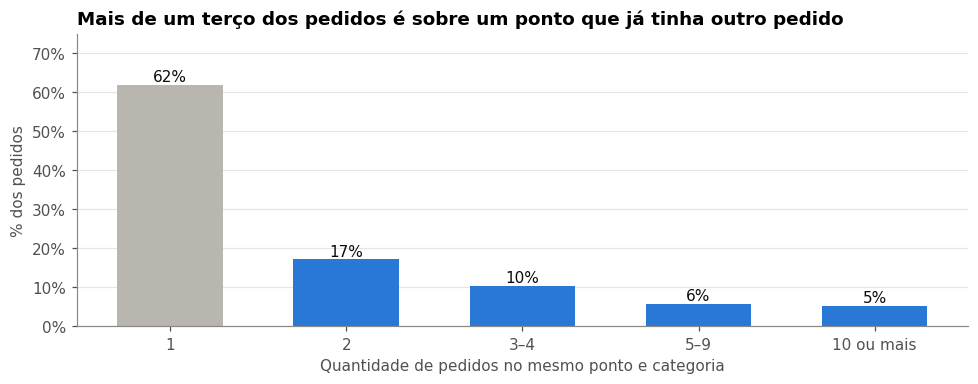

In [17]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(tab.index.astype(str), tab["% dos pedidos"], color=[CINZA] + [AZUL] * 4, width=0.6)
for i, v in enumerate(tab["% dos pedidos"]):
    ax.text(i, v + 1, f"{v:.0f}%", ha="center", color="#0b0b0b")
ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_ylim(0, 75)
ax.set_title("Mais de um terço dos pedidos é sobre um ponto que já tinha outro pedido")
ax.set_xlabel("Quantidade de pedidos no mesmo ponto e categoria"); ax.set_ylabel("% dos pedidos")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

*Limitação:* a base não traz identificação do solicitante, então não dá para separar "vários vizinhos" de "a mesma pessoa insistindo".
Nos dois casos, o sinal é o mesmo: **o problema já era conhecido**, e cada novo protocolo é trabalho duplicado. Pontos com centenas de pedidos
(ex.: varrição no Butantã) também podem indicar geolocalização padrão; por isso olhamos a distribuição inteira, e não só o máximo.

### P6 — Por quais canais o cidadão pede ajuda?

,% das solicitações
canal,
Aplicativo,"42,25"
Portal web,"26,45"
Central telefônica,"24,84"
Chatbot (WhatsApp),"6,46"


canal,Aplicativo,Central telefônica,Chatbot (WhatsApp),Portal web
categoria_zelaai,,,,
Bueiro entupido,"28,10","39,20","9,80","22,90"
Buraco na via,"59,70","15,50","2,60","22,10"
"Calçada, guia e poste","30,50","27,70","5,40","36,40"
Descarte irregular / entulho,"43,00","26,10","10,20","20,70"
Limpeza urbana e lixeiras,"52,00","21,10","4,60","22,30"
Árvore em via pública,"15,90","34,60","6,80","42,70"


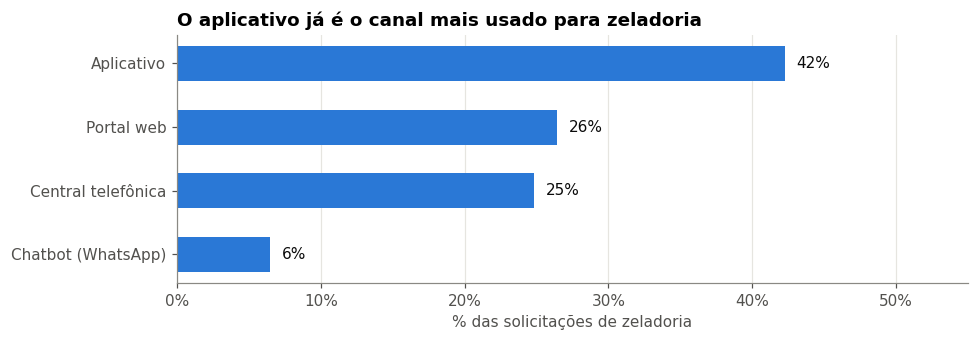

Canais digitais (app + portal + chatbot): 75% dos pedidos.


In [18]:
canais = {"MOBILE": "Aplicativo", "PORTAL": "Portal web", "CRM": "Central telefônica", "CHATBOT": "Chatbot (WhatsApp)"}
can = df["canal"].map(canais).value_counts(normalize=True).mul(100).rename("% das solicitações")
display(can.to_frame())
cruz = pd.crosstab(df["categoria_zelaai"], df["canal"].map(canais), normalize="index").mul(100).round(1)
display(cruz)

c = can.sort_values()
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(c.index, c.values, color=AZUL, height=0.55)
for i, v in enumerate(c.values):
    ax.text(v + 0.8, i, f"{v:.0f}%", va="center", color="#0b0b0b")
ax.xaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_xlim(0, 55)
ax.set_title("O aplicativo já é o canal mais usado para zeladoria")
ax.set_xlabel("% das solicitações de zeladoria"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
print(f"Canais digitais (app + portal + chatbot): {100 - can['Central telefônica']:.0f}% dos pedidos.")

## 5. Da análise para a solução: parâmetros para a priorização
O tempo típico de cada categoria indica quanto tempo de equipe cada ocorrência consome, e a taxa de pendência mostra onde a fila é maior. Esses números servem de referência para a regra de priorização do Zela Aí e ficam salvos em `parametros_categoria.csv`.

In [19]:
parametros = pd.DataFrame({
    "solicitacoes_trimestre": df["categoria_zelaai"].value_counts(),
    "mediana_dias_resolucao": tempo.drop("TODAS")["mediana"],
    "p90_dias_resolucao": tempo.drop("TODAS")["P90"],
    "pct_pendente": pend["% pendente"],
    "pct_em_ponto_repetido": por_cat,
}).round(1).sort_values("solicitacoes_trimestre", ascending=False)
parametros.index.name = "categoria_zelaai"
parametros.to_csv("parametros_categoria.csv")
parametros

,solicitacoes_trimestre,mediana_dias_resolucao,p90_dias_resolucao,pct_pendente,pct_em_ponto_repetido
categoria_zelaai,,,,,
Descarte irregular / entulho,34265,"1,00","6,00","2,70","51,90"
Buraco na via,29962,"4,00","19,00","28,60","32,80"
Árvore em via pública,17570,"12,00","40,00","29,50","23,10"
Limpeza urbana e lixeiras,14274,"1,00","4,00","0,60","45,40"
"Calçada, guia e poste",12167,"10,00","44,00","60,60","28,30"
Bueiro entupido,5757,"1,00","17,00","9,40","33,20"


## 6. Conclusões

**P1 — O que mais gera pedidos.** Descarte irregular / entulho e Buraco na via respondem juntos por **56%** das 113.995 solicitações de zeladoria do trimestre (≈1.239 por dia). São essas as categorias que o Zela Aí precisa tornar mais fáceis de registrar.

**P2 — Tempo de resolução.** A distribuição é **muito assimétrica**: a mediana geral é de **2 dias**, mas a média chega a **6,5 dias**, puxada por uma cauda longa. Por isso usamos a **mediana** como medida típica. As categorias são muito diferentes entre si: bueiro entupido, descarte irregular / entulho, limpeza urbana e lixeiras se resolvem em mediana de 1 dia, enquanto Árvore em via pública leva 12 dias. É essa diferença de "custo em tempo de equipe" que a priorização precisa considerar.

**P3 — A fila que ninguém vê.** **19,9%** dos pedidos (22.675 solicitações) continuavam abertos na extração. Em Calçada, guia e poste, **61%** seguiam na fila. Esse é exatamente o "não sei o andamento" do problema que escolhemos.

**P4 — Desigualdade territorial.** No tapa-buraco, a parcela de pedidos abertos varia de **13%** (Ermelino Matarazzo) a **52%** (Lapa) entre subprefeituras (coeficiente de variação de 30%). Onde o morador mora muda muito a chance de ter o buraco tapado. Isso justifica o ODS 10 e mostra que a priorização precisa ser **transparente** e comparável entre regiões. Na **Subprefeitura Sé**, região da equipe, a situação é melhor que a média: 15% de pedidos de zeladoria abertos contra 20% na cidade.

**P5 — Reclamações repetidas.** **38%** dos pedidos caem num ponto e categoria que já tinham outro pedido. No Zela Aí, esses 28.875 protocolos "a mais" virariam **apoios** a uma ocorrência já existente. Isso reduz retrabalho e dá à Prefeitura um sinal de quantas pessoas são afetadas.

**P6 — Canal.** O **aplicativo** já é o canal mais usado (42%), e os canais digitais somam **75%**. Há aderência para uma solução mobile/web.

**Para o Zela Aí:** os dados confirmam as três funcionalidades propostas (**apoio coletivo, priorização transparente e visão do bairro**) e fornecem os parâmetros de `parametros_categoria.csv` para o algoritmo de priorização.

**Limitações:** (1) um trimestre só, sem sazonalidade anual; (2) tempos de resolução subestimados pelo viés de censura dos pedidos ainda abertos; (3) número de pedidos ≠ número de problemas, como alerta a própria Prefeitura; (4) a base não identifica o solicitante, então repetição não prova que foram pessoas diferentes; (5) **iluminação pública não aparece** nos dados abertos do SP156 deste trimestre, então essa categoria do Zela Aí não pôde ser analisada aqui.